<a href="https://colab.research.google.com/github/saadat309/Digiskills-Excercises/blob/main/Ai_with_python_Exercise_3_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Toxic Comment Classification

This notebook demonstrates a complete pipeline for classifying toxic comments using a deep learning model. It covers data loading, preprocessing, model building, training, and evaluation.

In [3]:
import pandas as pd

# Load dataset
df = pd.read_csv("/content/toxic_comments_dataset.csv")

# First 10 records
print("First 10 Records:")
display(df.head(10))



First 10 Records:


,Comment_ID,Comment_Text,Toxicity_Label,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count,Platform,Topic,Moderation_Priority,Language
0,COM000001,The message targets a group unfairly and viola...,Identity_Attack,0,1,0,0,1,0.818,66,10,Community Chat,Sports,High,English
1,COM000002,Thank you for sharing this perspective with th...,Clean,1,0,0,0,0,0.069,58,9,News Comments,Entertainment,High,English
2,COM000003,That response is aggressive and not helpful.,Toxic,0,1,0,0,0,0.622,44,7,Social Media,Politics,Low,English
3,COM000004,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.010,61,9,Social Media,Entertainment,Low,English
4,COM000005,I respectfully disagree but I understand your ...,Clean,1,0,0,0,0,0.140,52,8,Blog,Sports,Low,English
5,COM000006,That response is aggressive and not helpful.,Toxic,0,1,0,0,0,0.729,44,7,Social Media,Technology,Low,English
6,COM000007,I respectfully disagree but I understand your ...,Clean,1,0,0,0,0,0.193,52,8,Blog,Entertainment,Low,English
7,COM000008,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.183,61,9,Forum,Gaming,Low,English
8,COM000009,This article provides useful information and c...,Clean,1,0,0,0,0,0.142,60,8,Social Media,Education,Medium,English
9,COM000010,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.153,61,9,Forum,Entertainment,Low,English


## 1. Data Loading and Initial Inspection

First, we load the dataset and perform an initial inspection to understand its structure and content.

In [4]:
# Last 8 records
print("Last 8 Records:")
display(df.tail(8))



Last 8 Records:


,Comment_ID,Comment_Text,Toxicity_Label,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count,Platform,Topic,Moderation_Priority,Language
29992,COM029993,Your message is unnecessarily hostile and offe...,Toxic,0,1,0,0,0,0.520,52,7,Forum,Gaming,Medium,English
29993,COM029994,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.195,61,9,News Comments,Sports,Medium,English
29994,COM029995,Thank you for sharing this perspective with th...,Clean,1,0,0,0,0,0.174,58,9,Community Chat,Gaming,Low,English
29995,COM029996,This article provides useful information and c...,Clean,1,0,0,0,0,0.013,60,8,Community Chat,Sports,Medium,English
29996,COM029997,I respectfully disagree but I understand your ...,Clean,1,0,0,0,0,0.050,52,8,Blog,Politics,Medium,English
29997,COM029998,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.078,61,9,Forum,Sports,Low,English
29998,COM029999,This article provides useful information and c...,Clean,1,0,0,0,0,0.003,60,8,Social Media,Sports,Medium,English
29999,COM030000,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.082,61,9,Community Chat,Education,High,English


Displaying the last few records helps confirm the dataset's integrity and observe any patterns at the end of the data.

In [5]:
# Dataset shape
print("Dataset Shape:", df.shape)



Dataset Shape: (30000, 15)


The `shape` attribute provides the number of rows and columns in the dataset, giving us an overview of its size.

In [6]:
# Column names and data types
print("\nColumn Names and Data Types:")
print(df.dtypes)



Column Names and Data Types:
Comment_ID              object
Comment_Text            object
Toxicity_Label          object
Clean                    int64
Toxic                    int64
Severe_Toxic             int64
Threat                   int64
Identity_Attack          int64
Toxicity_Score         float64
Comment_Length           int64
Word_Count               int64
Platform                object
Topic                   object
Moderation_Priority     object
Language                object
dtype: object


Checking column names and data types is crucial for understanding how to process each feature effectively. It helps identify categorical, numerical, and text fields.

In [7]:
# Statistical summary of numerical columns
print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.619300,0.380700,0.060033,0.048633,0.048933,0.324542,56.357633,8.340633
std,0.485567,0.485567,0.237553,0.215104,0.215732,0.302914,6.962596,0.972094
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,39.000000,6.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.079000,52.000000,8.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.161000,58.000000,8.000000
75%,1.000000,1.000000,0.000000,0.000000,0.000000,0.624000,61.000000,9.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,0.950000,71.000000,11.000000


A statistical summary of numerical columns provides insights into the distribution, central tendency, and spread of the data, helping to detect outliers or anomalies.

In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Records:", df.duplicated().sum())

Missing Values:
Comment_ID             0
Comment_Text           0
Toxicity_Label         0
Clean                  0
Toxic                  0
Severe_Toxic           0
Threat                 0
Identity_Attack        0
Toxicity_Score         0
Comment_Length         0
Word_Count             0
Platform               0
Topic                  0
Moderation_Priority    0
Language               0
dtype: int64

Number of Duplicate Records: 0


Before proceeding, we check for missing values and duplicate records to ensure data quality. Handling these issues is essential for reliable model training.

In [9]:
import re

def clean_text(text):
    text = text.lower()

    text = re.sub(r'<.*?>', ' ', text)

    text = text.encode('ascii', 'ignore').decode('ascii')

    text = re.sub(r'\d+', ' ', text)

    text = re.sub(r'[^a-z\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text

df['Cleaned_Comment'] = df['Comment_Text'].apply(clean_text)

display(df[['Comment_Text', 'Cleaned_Comment']].head(10))

,Comment_Text,Cleaned_Comment
0,The message targets a group unfairly and viola...,the message targets a group unfairly and viola...
1,Thank you for sharing this perspective with th...,thank you for sharing this perspective with th...
2,That response is aggressive and not helpful.,that response is aggressive and not helpful
3,I appreciate your explanation and the discussi...,i appreciate your explanation and the discussi...
4,I respectfully disagree but I understand your ...,i respectfully disagree but i understand your ...
5,That response is aggressive and not helpful.,that response is aggressive and not helpful
6,I respectfully disagree but I understand your ...,i respectfully disagree but i understand your ...
7,I appreciate your explanation and the discussi...,i appreciate your explanation and the discussi...
8,This article provides useful information and c...,this article provides useful information and c...
9,I appreciate your explanation and the discussi...,i appreciate your explanation and the discussi...


## 2. Text Preprocessing

Text preprocessing involves cleaning the raw comment text to prepare it for machine learning models. This custom `clean_text` function performs several steps:

*   **Lowercase conversion**: Converts all text to lowercase to treat words like 'Toxic' and 'toxic' as the same.
*   **Remove HTML tags**: Removes any HTML-like tags (e.g., `<br/>`) that might be present.
*   **Remove non-ASCII characters**: Converts text to ASCII and ignores characters that cannot be represented, standardizing the character set.
*   **Remove numbers**: Eliminates numerical digits, as they are often not relevant for sentiment or toxicity analysis.
*   **Remove special characters**: Keeps only alphabetic characters and spaces, removing punctuation and other symbols.
*   **Remove extra spaces**: Replaces multiple spaces with a single space and trims leading/trailing spaces.

The cleaned text is stored in a new column called `Cleaned_Comment`.

In [10]:
from sklearn.model_selection import train_test_split

# Input and target
X = df['Cleaned_Comment']
y = df['Toxicity_Label']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 24000
Testing samples: 6000

Training class distribution:
Toxicity_Label
Clean              14863
Toxic               5354
Severe_Toxic        1441
Identity_Attack     1175
Threat              1167
Name: count, dtype: int64

Testing class distribution:
Toxicity_Label
Clean              3716
Toxic              1339
Severe_Toxic        360
Identity_Attack     293
Threat              292
Name: count, dtype: int64


## 3. Data Splitting

We split the dataset into training and testing sets. This ensures that the model is trained on one portion of the data and evaluated on unseen data, providing an unbiased assessment of its performance. The `stratify` parameter is used to maintain the same class distribution in both sets, which is important for imbalanced datasets.

In [11]:
from tensorflow.keras.preprocessing.text import Tokenizer

# Create tokenizer
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")

# Fit tokenizer ONLY on training text
tokenizer.fit_on_texts(X_train)

# Convert training and testing text into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Vocabulary size:", len(tokenizer.word_index))
print("First training sequence:")
print(X_train_seq[0])

print("\nFirst testing sequence:")
print(X_test_seq[0])

Vocabulary size: 87
First training sequence:
[3, 10, 51, 54, 55, 48, 2, 46, 47, 56]

First testing sequence:
[11, 12, 13, 14, 3, 15, 16, 5, 9]


## 4. Tokenization and Sequence Padding

**Tokenization** is the process of converting text into numerical sequences that can be fed into a neural network. We use Keras's `Tokenizer` to:

*   Create a vocabulary of the most frequent words (here, up to 10,000 words).
*   Assign a unique integer to each word.
*   Convert text comments into sequences of these integers.

**Why `oov_token="<OOV>"`?** This token handles words not found in the vocabulary (Out-Of-Vocabulary) during tokenization.

We fit the tokenizer *only* on the training data to prevent data leakage from the test set.

In [12]:
import numpy as np

# Calculate sequence lengths
sequence_lengths = [len(seq) for seq in X_train_seq]

print("Minimum sequence length:", min(sequence_lengths))
print("Maximum sequence length:", max(sequence_lengths))
print("Average sequence length:", np.mean(sequence_lengths))
print("Median sequence length:", np.median(sequence_lengths))

Minimum sequence length: 6
Maximum sequence length: 11
Average sequence length: 8.35875
Median sequence length: 8.0


To prepare the sequences for a neural network, it's helpful to analyze their lengths. This helps determine an appropriate `max_length` for padding, ensuring all input sequences have a uniform length.

In [13]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Maximum sequence length based on the training data
max_length = 11

# Pad sequences
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training padded shape:", X_train_pad.shape)
print("Testing padded shape:", X_test_pad.shape)

print("\nFirst padded training sequence:")
print(X_train_pad[0])

print("\nFirst padded testing sequence:")
print(X_test_pad[0])

Training padded shape: (24000, 11)
Testing padded shape: (6000, 11)

First padded training sequence:
[ 3 10 51 54 55 48  2 46 47 56  0]

First padded testing sequence:
[11 12 13 14  3 15 16  5  9  0  0]


Since neural networks require input sequences of uniform length, **padding** is applied. `pad_sequences`:

*   Pads shorter sequences with zeros.
*   Truncates longer sequences.

Here, `max_length = 11` is chosen based on the analysis of sequence lengths. `padding='post'` adds zeros at the end, and `truncating='post'` removes words from the end if a sequence is too long.

In [14]:
from sklearn.preprocessing import LabelEncoder

# Encode target labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:")
print(label_encoder.classes_)

print("\nEncoded training labels:")
print(y_train_encoded[:10])

print("\nEncoded testing labels:")
print(y_test_encoded[:10])

Classes:
['Clean' 'Identity_Attack' 'Severe_Toxic' 'Threat' 'Toxic']

Encoded training labels:
[2 4 0 0 0 4 0 4 4 0]

Encoded testing labels:
[0 0 2 0 4 4 0 2 0 0]


## 5. Label Encoding

The target labels (e.g., 'Clean', 'Toxic') are categorical strings. Neural networks require numerical input, so we use `LabelEncoder` from `sklearn.preprocessing` to convert these categorical labels into numerical representations (e.g., 0, 1, 2, ...).

In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dropout, Dense

num_classes = len(label_encoder.classes_)

vocab_size = len(tokenizer.word_index) + 1

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=32
    ),

    GlobalAveragePooling1D(),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dropout(0.2),

    Dense(num_classes, activation='softmax')
])


model.build(input_shape=(None, max_length))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 11, 32)         │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,037 (15.77 KB)

 Trainable params: 4,037 (15.77 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Model Definition and Compilation

We define a sequential neural network model for multi-class text classification:

*   **`Embedding` Layer**: This layer converts integer-encoded words into dense vectors of a fixed size (`output_dim=32`). It learns semantic relationships between words.
    *   `input_dim` is the size of the vocabulary.
    *   `output_dim` is the dimensionality of the dense embedding.
*   **`GlobalAveragePooling1D` Layer**: This layer reduces the dimensionality of the sequence by averaging the embeddings across all words, providing a fixed-size output regardless of input length.
*   **`Dropout` Layers**: These layers randomly set a fraction of input units to 0 at each update during training, which helps prevent overfitting.
*   **`Dense` Layers**: These are fully connected layers.
    *   The first `Dense` layer has 32 units and uses a `relu` activation function.
    *   The final `Dense` layer has `num_classes` units (one for each toxicity label) and uses a `softmax` activation function, which outputs probabilities for each class.

**Compilation**: The model is compiled with:

*   `optimizer='adam'`: An adaptive learning rate optimization algorithm.
*   `loss='sparse_categorical_crossentropy'`: Suitable for multi-class classification when target labels are integers (not one-hot encoded).
*   `metrics=['accuracy']`: To monitor the accuracy during training.

In [17]:
history = model.fit(
    X_train_pad,
    y_train_encoded,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    shuffle=True,
    verbose=1
)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9158 - loss: 0.3022 - val_accuracy: 1.0000 - val_loss: 0.0107
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9992 - loss: 0.0103 - val_accuracy: 1.0000 - val_loss: 5.9950e-04
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9998 - loss: 0.0030 - val_accuracy: 1.0000 - val_loss: 1.2801e-04
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 4.0578e-05
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 1.0000 - loss: 7.7669e-04 - val_accuracy: 1.0000 - val_loss: 1.4676e-05
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9999 - loss: 7.9360e-04 - val_accuracy: 1.0000 - val_loss: 7.5574e-06
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9999 - loss: 4.8998e-04 - val_accuracy: 1.0000 - val_loss: 3.2379e-06
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 1.00

## 7. Model Training

The model is trained using the `fit` method. Here's a breakdown of the parameters:

*   **`X_train_pad`**: The padded input sequences for training.
*   **`y_train_encoded`**: The encoded target labels for training.
*   **`epochs=10`**: The number of times the model will iterate over the entire training dataset.
*   **`batch_size=32`**: The number of samples processed before the model's parameters are updated.
*   **`validation_split=0.2`**: A fraction of the training data (20% in this case) is reserved for validation during training. This helps monitor overfitting.
*   **`shuffle=True`**: Shuffles the training data before each epoch.
*   **`verbose=1`**: Displays training progress in detail.

In [19]:

test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test_encoded,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 2.8274e-07

Test Loss: 2.827444234299037e-07
Test Accuracy: 1.0


## 8. Model Evaluation

After training, the model's performance is evaluated on the unseen test dataset. The `model.evaluate` method calculates the loss and accuracy metrics.

In [20]:
from sklearn.metrics import confusion_matrix
import numpy as np

y_pred_prob = model.predict(X_test_pad)

y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test_encoded, y_pred)

print("Confusion Matrix:")
print(cm)

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Confusion Matrix:
[[3716    0    0    0    0]
 [   0  293    0    0    0]
 [   0    0  360    0    0]
 [   0    0    0  292    0]
 [   0    0    0    0 1339]]


## 9. Confusion Matrix

A **confusion matrix** is a table that is often used to describe the performance of a classification model on a set of test data for which the true values are known. It allows visualization of the performance of an algorithm. Here's how it's generated:

1.  **`model.predict(X_test_pad)`**: Generates probability predictions for each class on the test set.
2.  **`np.argmax(y_pred_prob, axis=1)`**: Converts these probabilities into hard class predictions by selecting the class with the highest probability.
3.  **`confusion_matrix(y_test_encoded, y_pred)`**: Compares the true encoded test labels with the predicted labels to construct the matrix.

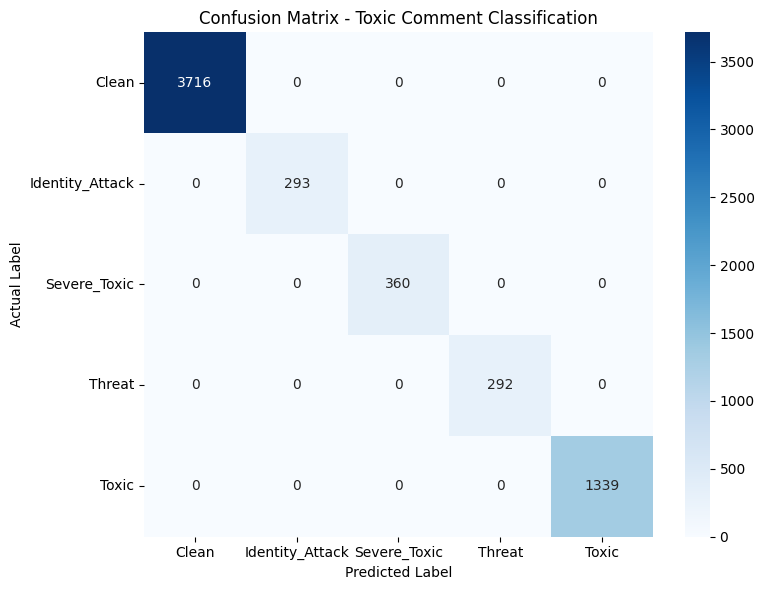

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Class names
class_names = label_encoder.classes_

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Confusion Matrix - Toxic Comment Classification')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

Visualizing the confusion matrix with a heatmap makes it easier to interpret. Each cell `(i, j)` in the matrix shows the number of instances that actually belong to class `i` but were predicted as class `j`. The diagonal elements represent correctly classified instances.

In [22]:
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(
    y_test_encoded,
    y_pred,
    target_names=label_encoder.classes_
)

print("Classification Report:")
print(report)

Classification Report:
                 precision    recall  f1-score   support

          Clean       1.00      1.00      1.00      3716
Identity_Attack       1.00      1.00      1.00       293
   Severe_Toxic       1.00      1.00      1.00       360
         Threat       1.00      1.00      1.00       292
          Toxic       1.00      1.00      1.00      1339

       accuracy                           1.00      6000
      macro avg       1.00      1.00      1.00      6000
   weighted avg       1.00      1.00      1.00      6000



## 10. Classification Report

The **classification report** provides a more detailed breakdown of the model's performance per class. It includes:

*   **Precision**: The proportion of positive identifications that were actually correct.
*   **Recall**: The proportion of actual positives that were identified correctly.
*   **F1-score**: The harmonic mean of precision and recall, providing a single metric that balances both.
*   **Support**: The number of actual occurrences of each class in the specified dataset.

These metrics are crucial for understanding how well the model performs for each specific toxicity category, especially in cases of class imbalance.

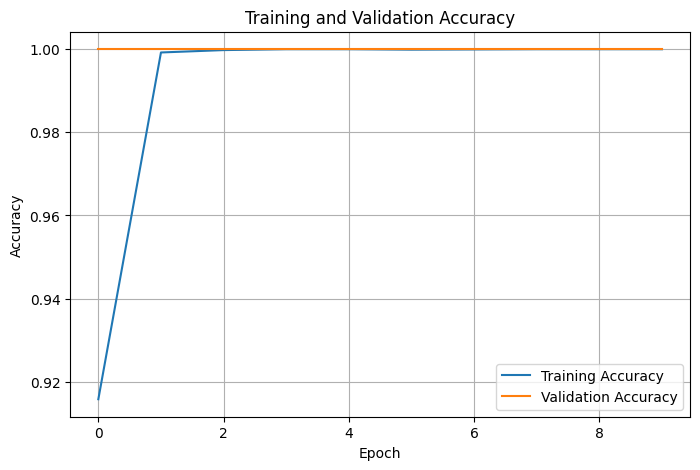

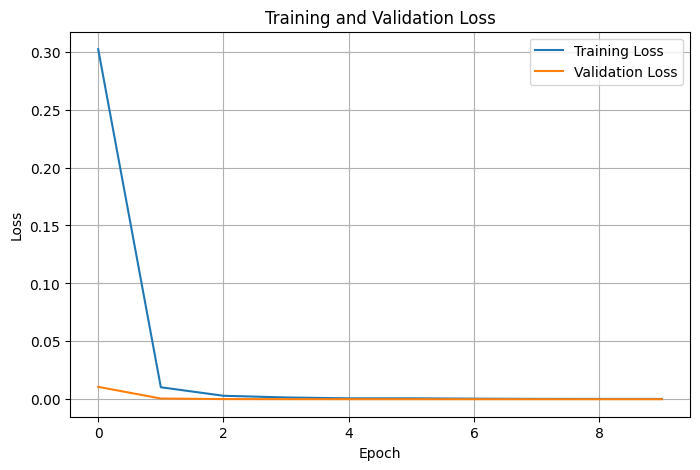

In [23]:
import matplotlib.pyplot as plt

# Accuracy curve
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


# Loss curve
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## 11. Training History Visualization

Plotting the training and validation accuracy and loss curves helps to:

*   **Monitor Model Learning**: Observe how the model's performance changes over epochs.
*   **Detect Overfitting**: If training accuracy continues to improve while validation accuracy plateaus or decreases, it indicates overfitting.
*   **Detect Underfitting**: If both training and validation accuracies are low, it suggests the model is underfitting.

These plots provide valuable insights into the training process and can guide decisions on hyperparameter tuning or model architecture adjustments.